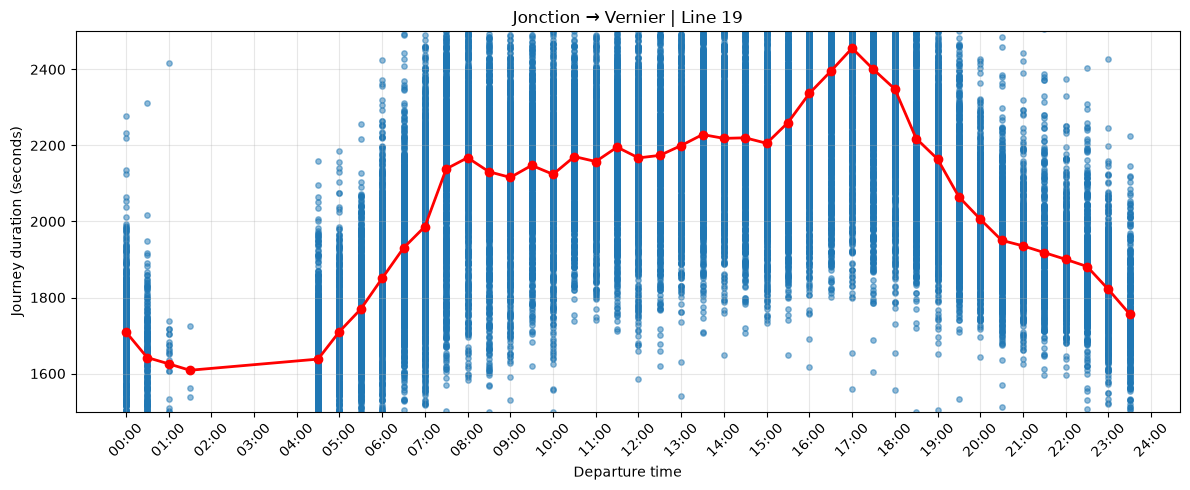

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("./data/bus19_durations.csv")


# Mean duration for each departure time
mean_duration = (
    df.groupby("departure_hour")["duration_seconds"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.scatter(
        df["departure_hour"],
        df["duration_seconds"],
        alpha=0.5,
        s=15
)

# draws the mean line
plt.plot(
    mean_duration.index,
    mean_duration.values,
    marker="o",
    color="red",
    linewidth=2,
    label="Mean duration"
)


plt.xticks(
        np.arange(0, 25, 1),
        [f"{h:02d}:00" for h in range(25)],
        rotation=45
    )

plt.xlabel("Departure time")
plt.ylabel("Journey duration (seconds)")
plt.title(f"Jonction → Vernier | Line 19")

plt.grid(alpha=0.3)

#plt.ylim(top=4000)
plt.ylim(1500, 2500)

plt.tight_layout()
plt.show()


 

In [4]:
df.head()

,line_id,duration,time_index,duration_seconds,departure_hour
0,85:881:19,0 days 00:27:00,0,1620.0,0.0
1,85:881:19,0 days 00:27:21,0,1641.0,0.0
2,85:881:19,0 days 00:28:00,0,1680.0,0.0
3,85:881:19,0 days 00:27:33,0,1653.0,0.0
4,85:881:19,0 days 00:27:59,0,1679.0,0.0


$$
\boxed{
duration_i \sim \text{Normal}(\mu_i,\sigma)
}
$$

$$
\boxed{
\mu_i = \alpha + \sum_{j=1}^{K} \beta_j B_j(x_i)
}
$$

Where:
* $x_i$ is departure time in hours, from 0 to 24.
* $B_j(x_i)$ is the value of spline basis function $j$.
* $\beta_j$ is its coefficient.
* $\sigma$ is residual journey-duration variation.

In [5]:
hours = sorted(df["departure_hour"].unique())
print(hours[0:5])
print(np.min(hours))
print(np.max(hours))

[np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(4.5)]
0.0
23.5


In [39]:
# Exploring basis function

from patsy import dmatrix, build_design_matrices

x_slots = np.arange(48) / 2  # 0, 0.5, ..., 23.5

B_spline = dmatrix(
    "bs(x, df=8, degree=1, include_intercept=False, "
    "lower_bound=-2.9375, upper_bound=26.4375) - 1",
    {"x": x_slots}
)


# Preserve Patsy's metadata
design_info = B_spline.design_info

B_slots = build_design_matrices(
    [design_info],
    {"x": x_slots}
)[0]

B_slots = np.asarray(B_slots, dtype=float)

B_df = pd.DataFrame(
    B_slots,
    index=[f"{int(x):02d}:{int((x % 1) * 60):02d}" for x in x_slots],
    columns=[f"B{i+1}" for i in range(B_slots.shape[1])]
)

#print(B_df.round(3).to_string())
k1, k7 = np.quantile(x_slots, [1/8, 7/8])

# Set boundaries so the basis functions have value 0.5
lower_bound = -k1
upper_bound = max(x_slots) * 2 - k7

print(f"LB {lower_bound} UB {upper_bound} k1 {k1} k7 {k7}")

print(B_slots[:5])   # first 5 rows
print(B_slots[-5:])  # last 5 rows

LB -2.9375 UB 26.4375 k1 2.9375 k7 20.5625
[[0.5        0.         0.         0.         0.         0.
  0.         0.        ]
 [0.58510638 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.67021277 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.75531915 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.84042553 0.         0.         0.         0.         0.
  0.         0.        ]]
[[0.         0.         0.         0.         0.         0.
  0.84042553 0.15957447]
 [0.         0.         0.         0.         0.         0.
  0.75531915 0.24468085]
 [0.         0.         0.         0.         0.         0.
  0.67021277 0.32978723]
 [0.         0.         0.         0.         0.         0.
  0.58510638 0.41489362]
 [0.         0.         0.         0.         0.         0.
  0.5        0.5       ]]


In [40]:
import pymc as pm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from patsy import dmatrix, build_design_matrices

# Extract data
x = df["departure_hour"].to_numpy(dtype=float)
y = df["duration_seconds"].to_numpy(dtype=float)

assert np.all(np.isfinite(x) & np.isfinite(y))


# Create cubic B-spline basis
# Construct 8 cubic B-spline basis functions over the 0–24 hour domain.
# Each basis function is a smooth, piecewise cubic polynomial (degree=3).
# include_intercept=False omits the constant basis component.
# Subtracting 1 removes the intercept column from the resulting design matrix,
# since the regression model already includes its own intercept.
B_spline = dmatrix(
    "bs(x, df=8, degree=1, include_intercept=False, "
    "lower_bound=-2.9375, upper_bound=26.4375) - 1",
    {"x": x}
)


# Preserve Patsy's metadata
design_info = B_spline.design_info

B = np.asarray(B_spline, dtype=float)

print("Observations:", len(y))
print("Basis shape:", B.shape)
print(len(x))
print(len(y))
B

Observations: 35632
Basis shape: (35632, 8)
35632
35632


array([[0.31125828, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.31125828, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.31125828, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.31125828, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.31125828, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.31125828, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(35632, 8))

In [7]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider())

IntSlider(value=0)

In [41]:
from pathlib import Path
import util
from pathlib import Path 
import pymc as pm
from importlib import reload
# in case we are editinng
reload(util)

with pm.Model() as model:

    # Overall average journey duration
    alpha = pm.Normal(
        "alpha",
        mu=y.mean(),
        sigma=500
    )

    # Spline coefficients
    # we learn 8 values
    w = pm.Normal(
        "w",
        mu=0,
        sigma=250,
        shape=B.shape[1]
    )

    # Expected duration
    # B has len(x) ; but we are not learning B
    mu = pm.Deterministic(
        "mu",
        alpha + pm.math.dot(B, w)
    )

    # Observation noise
    sigma = pm.HalfNormal(
        "sigma",
        sigma=300
    )

    # Likelihood
    duration = pm.Normal(
        "duration",
        mu=mu,
        sigma=sigma,
        observed=y
    )

    idata = util.sample_or_load(
                lambda: pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        target_accept=0.9,
        random_seed=42
    ), Path(f"chap4_splines_1.trace"))

In [42]:
# Regular grid of departure times
x_grid = np.linspace(0, 24, 200)

# Construct the same spline basis for prediction
B_grid = build_design_matrices(
    [design_info],
    {"x": x_grid}
)[0]

B_grid = np.asarray(B_grid, dtype=float)

# Extract posterior samples
alpha_samples = idata.posterior["alpha"].values
w_samples = idata.posterior["w"].values

# Calculate expected duration for every posterior draw
# Transpose B_grid to align matrix multiplication dimensions
# B_grid.T: (8, 200)
#
# Matrix multiplication:
# (4, 2000, 8) @ (8, 200) = (4, 2000, 200)
#
# Add a singleton dimension to alpha_samples:
# (4, 2000) -> (4, 2000, 1)
#
# Broadcasting adds the intercept to each of the 200 predictions
mu_samples = (
    alpha_samples[..., None]
    + np.matmul(w_samples, B_grid.T)
)

# Combine chains and draws
mu_samples = mu_samples.reshape(-1, len(x_grid))

# Posterior mean and 89% equal-tailed interval
mu_mean = mu_samples.mean(axis=0)
mu_interval = np.quantile(
    mu_samples,
    [0.055, 0.945],
    axis=0
)

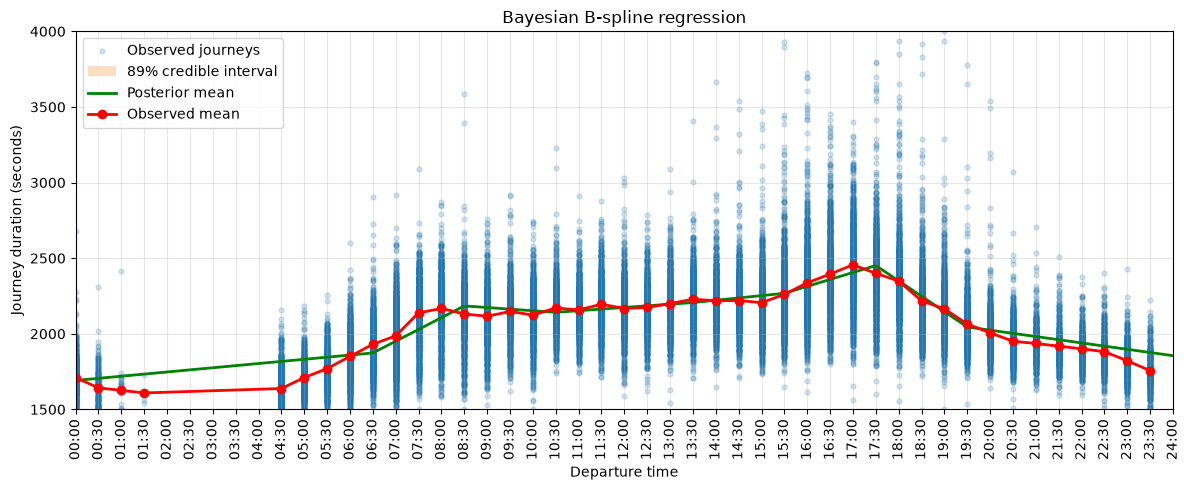

In [43]:
plt.figure(figsize=(12, 5))

# Individual journeys
plt.scatter(
    x,
    y,
    alpha=0.2,
    s=12,
    label="Observed journeys"
)

# Posterior uncertainty
plt.fill_between(
    x_grid,
    mu_interval[0],
    mu_interval[1],
    alpha=0.25,
    label="89% credible interval"
)

# Posterior mean
plt.plot(
    x_grid,
    mu_mean,
    color="green",
    linewidth=2,
    label="Posterior mean"
)

# Observed mean for each departure slot
observed_mean = (
    pd.DataFrame({"x": x, "y": y})
    .groupby("x")["y"]
    .mean()
    .sort_index()
)

plt.plot(
    observed_mean.index,
    observed_mean.values,
    color="red",
    marker="o",
    linewidth=2,
    label="Observed mean"
)

plt.xlim(0, 24)
plt.ylim(1500, 4000)

plt.xticks(
    np.arange(0, 24.5, 0.5),
    [f"{h:02d}:{m:02d}" for h in range(24) for m in (0, 30)] + ["24:00"],
    rotation=90
)

plt.xlabel("Departure time")
plt.ylabel("Journey duration (seconds)")
plt.title("Bayesian B-spline regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()